In [61]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Task 01: Hotel Booking Demand Analysis

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [63]:
PATH = '/content/drive/MyDrive/Task_01_AI_ML/dataset/hotel_bookings.csv'
df = pd.read_csv(PATH)
raw_rows, raw_cols = df.shape   # baad mein before/after comparison ke liye
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [64]:
pd.set_option('display.max_columns', None)

display(df.head())
display(df.tail())
display(df.sample(5, random_state=42))


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.0,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.0,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.0,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.0,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
30946,Resort Hotel,0,203,2016,December,49,2,2,5,2,0.0,0,BB,GBR,Direct,Direct,0,0,0,F,F,4,No Deposit,250.0,NaN,0,Transient,66.8,0,0,Check-Out,2016-12-09
40207,City Hotel,1,82,2015,July,29,16,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,76.5,0,0,Canceled,2015-07-16
103708,City Hotel,0,25,2016,December,53,27,0,3,3,0.0,0,BB,BRA,Offline TA/TO,TA/TO,0,0,0,A,K,2,No Deposit,220.0,NaN,0,Transient-Party,60.0,0,1,Check-Out,2016-12-30
85144,City Hotel,0,1,2016,March,11,9,0,1,1,0.0,0,BB,SWE,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient-Party,95.0,0,0,Check-Out,2016-03-10
109991,City Hotel,0,70,2017,April,16,16,2,2,2,0.0,0,SC,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,108.0,0,0,Check-Out,2017-04-20


In [65]:
df.info()
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.columns.tolist())
print(df.isnull().sum()[df.isnull().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [66]:
numerical_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print("Numerical:", len(numerical_cols), numerical_cols)
print("Categorical:", len(categorical_cols), categorical_cols)
print("Date column (abhi string hai): reservation_status_date")

Numerical: 20 ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical: 12 ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']
Date column (abhi string hai): reservation_status_date


### 1.7 Understanding the Dataset

**What the dataset is about:**
This dataset contains booking records of two hotels in Portugal: a City Hotel and a Resort Hotel. Each row is one booking and describes when it was made, how long the guest stayed, who the guest was, how much was charged, and whether the booking was cancelled.

**Dataset size:**
The raw dataset contains 119,390 rows and 32 columns. Each row is a single booking and each column is a feature describing that booking.

**Numerical columns** (for example `lead_time`, `adr`, `stays_in_week_nights`, `adults`):
These columns contain measurable values. They are used to calculate averages, medians, standard deviation and correlations, and to study relationships such as whether a longer lead time is linked to a higher chance of cancellation.

**Categorical columns** (for example `hotel`, `meal`, `country`, `market_segment`):
These columns contain labels or groups. They are used for frequency counts and group-wise comparisons, such as which country sends the most guests or which market segment has the highest cancellation rate.

**Date/Time columns** (`arrival_date_year`, `arrival_date_month`, `reservation_status_date`):
Date information helps us study trends over time, such as seasonal patterns in bookings and prices. The column `reservation_status_date` is currently stored as text and will be converted to a proper datetime type during data cleaning.

**Why this step matters:**
Separating numerical, categorical and date columns tells us which statistical methods and charts are suitable for each feature, so the rest of the analysis stays accurate and meaningful.

## 2. Data Cleaning & Preprocessing
### 2.1 Checking Missing Values

,Missing,Percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


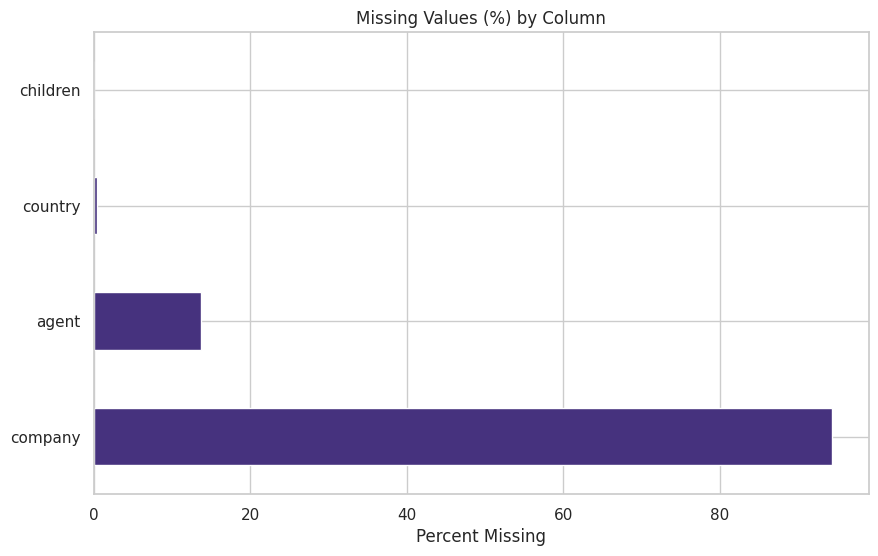

In [67]:
missing = df.isnull().sum()
percent = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing': missing, 'Percent': percent})
missing_df = missing_df[missing_df.Missing > 0].sort_values('Missing', ascending=False)
display(missing_df)

missing_df['Percent'].plot(kind='barh', title='Missing Values (%) by Column')
plt.xlabel('Percent Missing')
plt.show()

**Observation:**
Four columns contain missing values. The `company` column is missing in about 94% of records, `agent` in about 14%, `country` in about 0.4%, and `children` in only 4 records. The missing percentage decides the handling method: very high missing columns are dropped, while low missing columns are filled with a suitable value.

### 2.2 Handling Missing Values

In [68]:
# company: ~94% missing, too sparse to be useful, so drop the column
df.drop(columns='company', inplace=True)

# agent: missing means the booking had no travel agent, so fill with 0
df['agent'] = df['agent'].fillna(0)

# country: categorical, fill with the most frequent value (mode)
df['country'] = df['country'].fillna(df['country'].mode()[0])

# children: only 4 missing rows, typical value is 0
df['children'] = df['children'].fillna(0)

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


**Missing Value Handling Summary:**
- `company` (94.3% missing): the column was dropped because it is too sparse to give reliable information.
- `agent` (13.7% missing): filled with 0, because a missing value means the booking was made without an agent.
- `country` (0.41% missing): filled with the mode, since it is a categorical column with very few missing values.
- `children` (4 rows): filled with 0, the most common value.

### 2.3 Checking and Removing Duplicate Records

In [69]:
print("Duplicates before:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Duplicates after:", df.duplicated().sum())
print("Shape after removing duplicates:", df.shape)

Duplicates before: 32020
Duplicates after: 0
Shape after removing duplicates: (87370, 31)


**Duplicate Records:**
The dataset contained duplicate records, meaning rows that are identical in every column. These were removed because duplicates give extra weight to the same booking and bias statistics such as averages and cancellation rates. After removal, the duplicate count is 0.

### 2.4 Correcting Data Types

In [70]:
print("Data types BEFORE:")
display(df[['children', 'agent', 'reservation_status_date']].dtypes)

# Convert date text to datetime
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# Convert float columns that hold whole numbers to integers
df['children'] = df['children'].astype(int)
df['agent'] = df['agent'].astype(int)

# Build one proper arrival date column
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d')

# Readable label for graphs later
df['cancellation_status'] = df['is_canceled'].map({0: 'Not Cancelled', 1: 'Cancelled'})

print("Data types AFTER:")
display(df[['children', 'agent', 'reservation_status_date', 'arrival_date', 'cancellation_status']].dtypes)

Data types BEFORE:


,0
children,float64
agent,float64
reservation_status_date,object


Data types AFTER:


,0
children,int64
agent,int64
reservation_status_date,datetime64[ns]
arrival_date,datetime64[ns]
cancellation_status,object


**Data Type Corrections:**
- `reservation_status_date` was stored as text and was converted to datetime so that time-based analysis is possible.
- `children` and `agent` were stored as floats only because of missing values; after filling them they were converted to integers.
- A new `arrival_date` column was created by combining the arrival year, month and day, which will be used for trend charts.
- A new `cancellation_status` column gives readable labels (Cancelled / Not Cancelled) for graphs.

### 2.5 Renaming Columns

In [71]:
rename_map = {
    'adr': 'avg_daily_rate',
    'is_canceled': 'is_cancelled',
    'arrival_date_year': 'arrival_year',
    'arrival_date_month': 'arrival_month',
    'arrival_date_week_number': 'arrival_week',
    'arrival_date_day_of_month': 'arrival_day',
    'stays_in_weekend_nights': 'weekend_nights',
    'stays_in_week_nights': 'week_nights',
    'reserved_room_type': 'reserved_room',
    'assigned_room_type': 'assigned_room',
    'required_car_parking_spaces': 'parking_spaces',
    'total_of_special_requests': 'special_requests'
}
df.rename(columns=rename_map, inplace=True)
print(df.columns.tolist())

['hotel', 'is_cancelled', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_week', 'arrival_day', 'weekend_nights', 'week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room', 'assigned_room', 'booking_changes', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'avg_daily_rate', 'parking_spaces', 'special_requests', 'reservation_status', 'reservation_status_date', 'arrival_date', 'cancellation_status']


**Column Renaming:**
Some column names were long or unclear, so they were renamed to be short, consistent and easy to understand (for example `adr` became `avg_daily_rate`, and `stays_in_weekend_nights` became `weekend_nights`). Clear names make the code and charts easier to read.

### 2.6 Checking and Handling Invalid Values

In [72]:
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['total_nights'] = df['weekend_nights'] + df['week_nights']

print("Negative rate:", (df.avg_daily_rate < 0).sum())
print("Zero rate:", (df.avg_daily_rate == 0).sum())
print("Extreme rate (>=5000):", (df.avg_daily_rate >= 5000).sum())
print("Zero guests:", (df.total_guests == 0).sum())
print("Zero nights:", (df.total_nights == 0).sum())

before = len(df)
df = df[(df.avg_daily_rate >= 0) & (df.avg_daily_rate < 5000)]
df = df[df.total_guests > 0]
df = df[df.total_nights > 0]
df.reset_index(drop=True, inplace=True)

print("Rows before:", before)
print("Rows after:", len(df))
print("Rows removed:", before - len(df))

Negative rate: 1
Zero rate: 1778
Extreme rate (>=5000): 1
Zero guests: 166
Zero nights: 651
Rows before: 87370
Rows after: 86611
Rows removed: 759


**Invalid Values:**
Rows that are logically impossible were removed: a negative average daily rate, an extreme rate of 5,000 or more (an obvious data-entry error), bookings with zero guests, and bookings with zero nights stayed. Such rows would distort averages and charts. Rows with a rate of exactly 0 were kept, because they can represent complimentary or special bookings.

### 2.7 Verifying the Cleaned Dataset

In [73]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Shape:", df.shape)
display(df.dtypes)
display(df.describe())

comparison = pd.DataFrame({
    'Metric': ['Rows', 'Columns', 'Missing Values', 'Duplicate Rows', 'Invalid Rows Removed'],
    'Before Cleaning': [raw_rows, raw_cols, 5, 32020, 'Not checked'],
    'After Cleaning': [df.shape[0], df.shape[1], 0, 0, 759]
})
display(comparison)

Missing values: 0
Duplicates: 0
Shape: (86611, 35)


,0
hotel,object
is_cancelled,int64
lead_time,int64
arrival_year,int64
arrival_month,object
arrival_week,int64
arrival_day,int64
weekend_nights,int64
week_nights,int64
adults,int64


,is_cancelled,lead_time,arrival_year,arrival_week,arrival_day,weekend_nights,week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,days_in_waiting_list,avg_daily_rate,parking_spaces,special_requests,reservation_status_date,arrival_date,total_guests,total_nights
count,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611.000000,86611,86611,86611.000000,86611.000000
mean,0.276916,80.312905,2016.212225,26.823787,15.817517,1.011627,2.642216,1.880662,0.139347,0.010865,0.036300,0.030573,0.184445,0.268211,80.968918,0.750494,107.194882,0.084724,0.700269,2016-08-31 15:03:45.574118656,2016-09-15 14:58:28.348823808,2.030874,3.653843
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014-10-17 00:00:00,2015-07-01 00:00:00,1.000000,1.000000
25%,0.000000,12.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,72.900000,0.000000,0.000000,2016-03-19 00:00:00,2016-04-02 00:00:00,2.000000,2.000000
50%,0.000000,50.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,99.000000,0.000000,0.000000,2016-09-08 00:00:00,2016-09-20 00:00:00,2.000000,3.000000
75%,1.000000,126.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,0.000000,134.450000,0.000000,1.000000,2017-03-06 00:00:00,2017-04-02 00:00:00,2.000000,5.000000
max,1.000000,709.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,18.000000,535.000000,391.000000,510.000000,8.000000,5.000000,2017-09-14 00:00:00,2017-08-31 00:00:00,55.000000,69.000000
std,0.447477,86.077752,0.685998,13.650983,8.835537,1.027546,2.035277,0.622246,0.456960,0.113858,0.187037,0.370594,1.737417,0.709995,109.913621,10.031035,51.293619,0.282301,0.832662,NaN,NaN,0.790702,2.735862


,Metric,Before Cleaning,After Cleaning
0,Rows,119390,86611
1,Columns,32,35
2,Missing Values,5,0
3,Duplicate Rows,32020,0
4,Invalid Rows Removed,Not checked,759


**Verification:**
After cleaning, the dataset has no missing values and no duplicate records, all columns have suitable data types, and impossible values have been removed. The cleaned dataset is now reliable for exploratory analysis.

## 3. Exploratory Data Analysis (EDA)
### 3.1 Dataset Overview

In [74]:
print("Shape:", df.shape)
print("Date range:", df['arrival_date'].min().date(), "to", df['arrival_date'].max().date())

print("\nBookings per hotel:")
print(df['hotel'].value_counts())

print("\nOverall cancellation rate (%):", round(df['is_cancelled'].mean()*100, 2))
print("\nCancellation rate by hotel (%):")
print((df.groupby('hotel')['is_cancelled'].mean()*100).round(2))

Shape: (86611, 35)
Date range: 2015-07-01 to 2017-08-31

Bookings per hotel:
hotel
City Hotel      53040
Resort Hotel    33571
Name: count, dtype: int64

Overall cancellation rate (%): 27.69

Cancellation rate by hotel (%):
hotel
City Hotel      30.21
Resort Hotel    23.72
Name: is_cancelled, dtype: float64


**Observation:**
The cleaned dataset has [86,611] bookings from [date] to [date]. The City Hotel has [X] bookings and the Resort Hotel has [Y]. The overall cancellation rate is [27.69]%, which means roughly one in four bookings is cancelled. The cancellation rate is [higher/lower] for the [City/Resort] Hotel.

### 3.2 Frequency of Categories

In [75]:
for col in ['hotel', 'meal', 'market_segment', 'customer_type', 'deposit_type']:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())
    print((df[col].value_counts(normalize=True)*100).round(2))

print("\nTop 10 countries:")
print(df['country'].value_counts().head(10))


--- hotel ---
hotel
City Hotel      53040
Resort Hotel    33571
Name: count, dtype: int64
hotel
City Hotel      61.24
Resort Hotel    38.76
Name: proportion, dtype: float64

--- meal ---
meal
BB           67394
SC            9346
HB            9029
Undefined      483
FB             359
Name: count, dtype: int64
meal
BB           77.81
SC           10.79
HB           10.42
Undefined     0.56
FB            0.41
Name: proportion, dtype: float64

--- market_segment ---
market_segment
Online TA        51280
Offline TA/TO    13745
Direct           11646
Groups            4889
Corporate         4145
Complementary      682
Aviation           222
Undefined            2
Name: count, dtype: int64
market_segment
Online TA        59.21
Offline TA/TO    15.87
Direct           13.45
Groups            5.64
Corporate         4.79
Complementary     0.79
Aviation          0.26
Undefined         0.00
Name: proportion, dtype: float64

--- customer_type ---
customer_type
Transient          71347
Transient-

**Observation:**
The most common meal plan is [BB], the most common market segment is [Online TA], the most common customer type is [Transient] and the most frequent guest country is [PRT]. The mode of a categorical column tells us which group dominates the business.

### 3.3 Outlier Detection

In [76]:
def count_outliers(series):
    Q1, Q3 = series.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    low, high = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n = ((series < low) | (series > high)).sum()
    return pd.Series({'Lower Bound': round(low,2), 'Upper Bound': round(high,2),
                      'Outliers': n, 'Outlier %': round(n/len(series)*100,2)})

outlier_df = pd.DataFrame({c: count_outliers(df[c]) for c in
                           ['lead_time','avg_daily_rate','total_nights','days_in_waiting_list']}).T
display(outlier_df)

,Lower Bound,Upper Bound,Outliers,Outlier %
lead_time,-159.00,297.00,2353.0,2.72
avg_daily_rate,-19.42,226.77,2508.0,2.90
total_nights,-2.50,9.50,2990.0,3.45
days_in_waiting_list,0.00,0.00,854.0,0.99


**Observation:**
Outliers were detected using the IQR method (values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR). `lead_time` has [N] outliers ([x]%), `avg_daily_rate` has [N] ([x]%). These are genuine but unusual bookings (for example very early bookings or peak-season prices), so they were kept in the data. Median-based measures are used where outliers matter.

### 3.4 Group-wise Analysis

In [77]:
print("Average daily rate by hotel:")
print(df.groupby('hotel')['avg_daily_rate'].mean().round(2))

print("\nAverage daily rate by market segment:")
print(df.groupby('market_segment')['avg_daily_rate'].mean().round(2).sort_values(ascending=False))

print("\nCancellation rate (%) by deposit type:")
print((df.groupby('deposit_type')['is_cancelled'].mean()*100).round(2))

print("\nCancellation rate (%) by market segment:")
print((df.groupby('market_segment')['is_cancelled'].mean()*100).round(2).sort_values(ascending=False))

print("\nAverage lead time: cancelled vs not cancelled:")
print(df.groupby('cancellation_status')['lead_time'].mean().round(1))

month_order = ['January','February','March','April','May','June','July',
               'August','September','October','November','December']
print("\nBookings per month:")
print(df['arrival_month'].value_counts().reindex(month_order))
print("\nAverage daily rate per month:")
print(df.groupby('arrival_month')['avg_daily_rate'].mean().reindex(month_order).round(2))

Average daily rate by hotel:
hotel
City Hotel      111.66
Resort Hotel    100.15
Name: avg_daily_rate, dtype: float64

Average daily rate by market segment:
market_segment
Online TA        118.91
Direct           118.08
Aviation         102.43
Offline TA/TO     82.20
Groups            75.60
Corporate         69.17
Undefined         15.00
Complementary      3.14
Name: avg_daily_rate, dtype: float64

Cancellation rate (%) by deposit type:
deposit_type
No Deposit    26.88
Non Refund    94.70
Refundable    24.30
Name: is_cancelled, dtype: float64

Cancellation rate (%) by market segment:
market_segment
Undefined        100.00
Online TA         35.55
Groups            27.22
Aviation          19.82
Offline TA/TO     14.94
Direct            14.88
Corporate         12.23
Complementary     12.17
Name: is_cancelled, dtype: float64

Average lead time: cancelled vs not cancelled:
cancellation_status
Cancelled        105.8
Not Cancelled     70.5
Name: lead_time, dtype: float64

Bookings per month:


**Observation:**
[Write 3 to 4 findings with numbers, e.g. which hotel has the higher average rate, which market segment cancels most, which deposit type has the highest cancellation rate, whether cancelled bookings have longer lead times, and which months are busiest and most expensive.]

## 4. Statistical Analysis aur ### 4.1 Descriptive Statistics

In [78]:
stat_cols = ['lead_time', 'avg_daily_rate', 'total_nights', 'total_guests',
             'special_requests', 'booking_changes']

stats = pd.DataFrame({
    'Mean': df[stat_cols].mean(),
    'Median': df[stat_cols].median(),
    'Mode': [df[c].mode()[0] for c in stat_cols],
    'Min': df[stat_cols].min(),
    'Max': df[stat_cols].max(),
    'Range': df[stat_cols].max() - df[stat_cols].min(),
    'Std Dev': df[stat_cols].std(),
    'Variance': df[stat_cols].var()
}).round(2)
display(stats)

,Mean,Median,Mode,Min,Max,Range,Std Dev,Variance
lead_time,80.31,50.0,0.0,0.0,709.0,709.0,86.08,7409.38
avg_daily_rate,107.19,99.0,75.0,0.0,510.0,510.0,51.29,2631.04
total_nights,3.65,3.0,3.0,1.0,69.0,68.0,2.74,7.48
total_guests,2.03,2.0,2.0,1.0,55.0,54.0,0.79,0.63
special_requests,0.70,0.0,0.0,0.0,5.0,5.0,0.83,0.69
booking_changes,0.27,0.0,0.0,0.0,18.0,18.0,0.71,0.50


**Observation:**
For `lead_time`, the mean is [80.31] days but the median is [50] days. Since the mean is higher than the median, the distribution is right-skewed: a few bookings made very far in advance pull the average up. The standard deviation of [86.08] days is larger than the mean, which shows very high variation in how early guests book. For `avg_daily_rate`, [write your mean, median and std dev and what they show].

### 4.2 Mean, Median and Mode Explained

In [79]:
col = 'lead_time'
manual_mean = df[col].sum() / len(df)     # Mean = Σx / n
print("Manual mean   :", round(manual_mean, 2))
print("Pandas mean   :", round(df[col].mean(), 2))
print("Median        :", df[col].median())
print("Mode          :", df[col].mode()[0])

Manual mean   : 80.31
Pandas mean   : 80.31
Median        : 50.0
Mode          : 0


**Mean = Σx / n**, where Σx is the sum of all values and n is the number of observations. The manual calculation matches the Pandas result, which verifies it.

The median is the middle value when data is sorted. It is more reliable than the mean when extreme values exist. In this dataset the median `lead_time` ([50] days) describes a typical booking better than the mean ([80.31] days), because very long lead times inflate the mean.

### 4.3 Standard Deviation and Variation

In [80]:
cv = (df[stat_cols].std() / df[stat_cols].mean() * 100).round(1)
print("Coefficient of variation (%):")
print(cv.sort_values(ascending=False))

Coefficient of variation (%):
booking_changes     264.7
special_requests    118.9
lead_time           107.2
total_nights         74.9
avg_daily_rate       47.9
total_guests         38.9
dtype: float64


**Observation:**
The coefficient of variation (std dev divided by mean) allows variation to be compared across columns with different units. `[column]` shows the greatest relative variation, while `[column]` is the most consistent.

### 4.4 Correlation Analysis

In [81]:
corr_cols = ['is_cancelled','lead_time','total_nights','total_guests','avg_daily_rate',
             'special_requests','booking_changes','previous_cancellations',
             'is_repeated_guest','parking_spaces','days_in_waiting_list']
corr = df[corr_cols].corr()
display(corr.round(2))

print("\nCorrelation with cancellation (strongest first):")
print(corr['is_cancelled'].drop('is_cancelled').sort_values(key=abs, ascending=False).round(3))

,is_cancelled,lead_time,total_nights,total_guests,avg_daily_rate,special_requests,booking_changes,previous_cancellations,is_repeated_guest,parking_spaces,days_in_waiting_list
is_cancelled,1.00,0.18,0.08,0.10,0.13,-0.12,-0.09,0.05,-0.08,-0.19,0.00
lead_time,0.18,1.00,0.32,0.12,0.02,0.03,0.08,0.01,-0.14,-0.09,0.13
total_nights,0.08,0.32,1.00,0.11,0.04,0.04,0.06,-0.02,-0.11,-0.05,-0.01
total_guests,0.10,0.12,0.11,1.00,0.41,0.13,0.00,-0.05,-0.16,0.03,-0.02
avg_daily_rate,0.13,0.02,0.04,0.41,1.00,0.15,0.01,-0.05,-0.14,0.04,-0.04
special_requests,-0.12,0.03,0.04,0.13,0.15,1.00,0.02,0.00,0.00,0.05,-0.05
booking_changes,-0.09,0.08,0.06,0.00,0.01,0.02,1.00,-0.01,0.01,0.05,0.02
previous_cancellations,0.05,0.01,-0.02,-0.05,-0.05,0.00,-0.01,1.00,0.21,-0.00,0.00
is_repeated_guest,-0.08,-0.14,-0.11,-0.16,-0.14,0.00,0.01,0.21,1.00,0.08,-0.01
parking_spaces,-0.19,-0.09,-0.05,0.03,0.04,0.05,0.05,-0.00,0.08,1.00,-0.02



Correlation with cancellation (strongest first):
parking_spaces           -0.186
lead_time                 0.183
avg_daily_rate            0.127
special_requests         -0.122
total_guests              0.098
booking_changes          -0.094
is_repeated_guest        -0.084
total_nights              0.081
previous_cancellations    0.051
days_in_waiting_list      0.005
Name: is_cancelled, dtype: float64


**Observation:**
The correlation coefficient ranges from −1 to +1. The strongest relationship with cancellation is [column] ([r value], [positive/negative]), followed by [column] ([r]). [Explain in one sentence what this means in business terms.] Most other correlations are weak (close to 0), which means no strong linear relationship exists between them. Correlation does not prove causation.

## 5. Data Visualization

In [82]:
import os
IMG = '/content/drive/MyDrive/Task_01_AI_ML/images/'
os.makedirs(IMG, exist_ok=True)
month_order = ['January','February','March','April','May','June','July',
               'August','September','October','November','December']

def save(n):
    plt.tight_layout()
    plt.savefig(f'{IMG}visualization_{n:02d}.png', dpi=300, bbox_inches='tight')
    plt.show()

5.1 Histogram (lead_time)

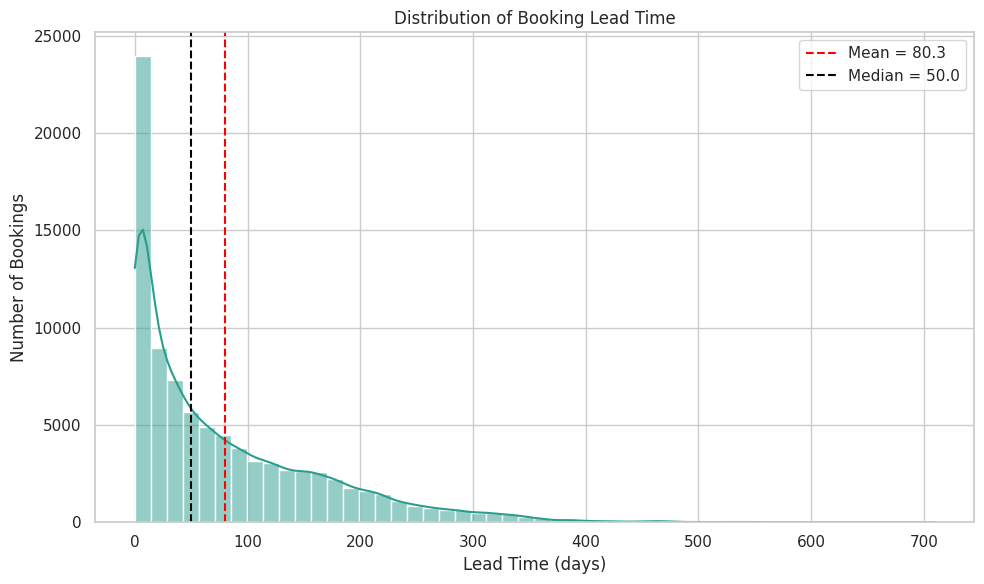

In [83]:
plt.figure(figsize=(10,6))
sns.histplot(df['lead_time'], bins=50, kde=True, color='#2a9d8f')
plt.axvline(df['lead_time'].mean(), color='red', linestyle='--', label=f"Mean = {df['lead_time'].mean():.1f}")
plt.axvline(df['lead_time'].median(), color='black', linestyle='--', label=f"Median = {df['lead_time'].median():.1f}")
plt.title('Distribution of Booking Lead Time'); plt.xlabel('Lead Time (days)'); plt.ylabel('Number of Bookings')
plt.legend(); save(1)

5.2 Bar Chart (average rate by market segment)

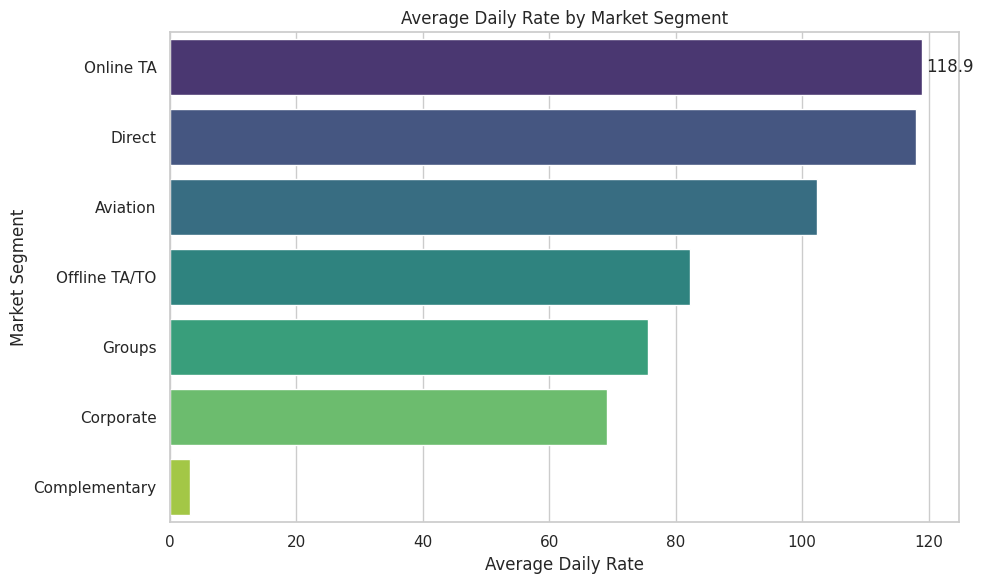

In [84]:
seg = df[~df['market_segment'].isin(['Undefined'])].groupby('market_segment')['avg_daily_rate'].mean().sort_values(ascending=False)
plt.figure(figsize=(10,6))
ax = sns.barplot(x=seg.values, y=seg.index, palette='viridis')
ax.bar_label(ax.containers[0], fmt='%.1f', padding=3)
plt.title('Average Daily Rate by Market Segment'); plt.xlabel('Average Daily Rate'); plt.ylabel('Market Segment')
save(2)

5.3 Pie Chart (market segment share)

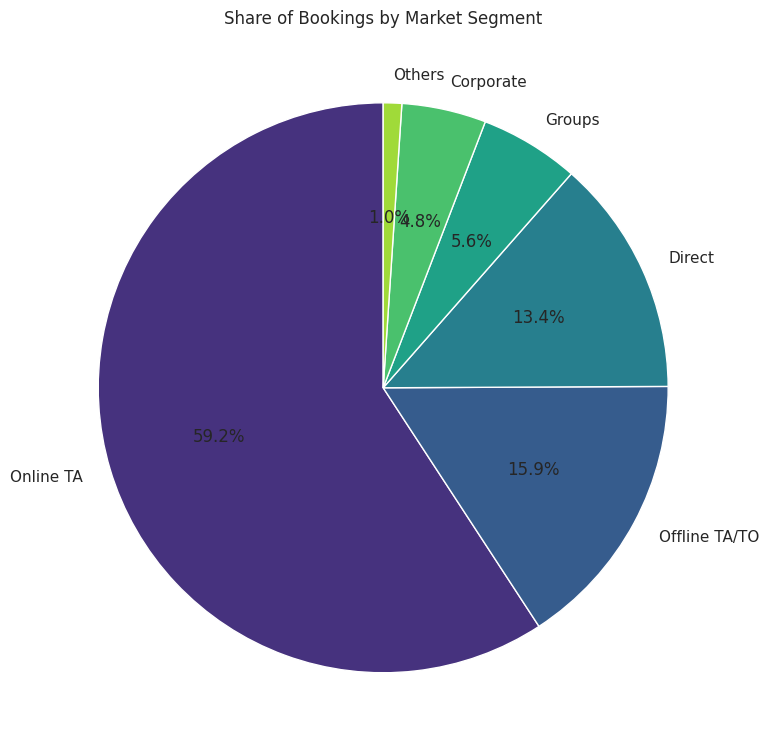

In [85]:
vc = df['market_segment'].value_counts()
top = vc.head(5).copy(); top['Others'] = vc.iloc[5:].sum()
plt.figure(figsize=(8,8))
plt.pie(top, labels=top.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('viridis', len(top)))
plt.title('Share of Bookings by Market Segment'); save(3)

5.4 Scatter Plot (guests vs rate)

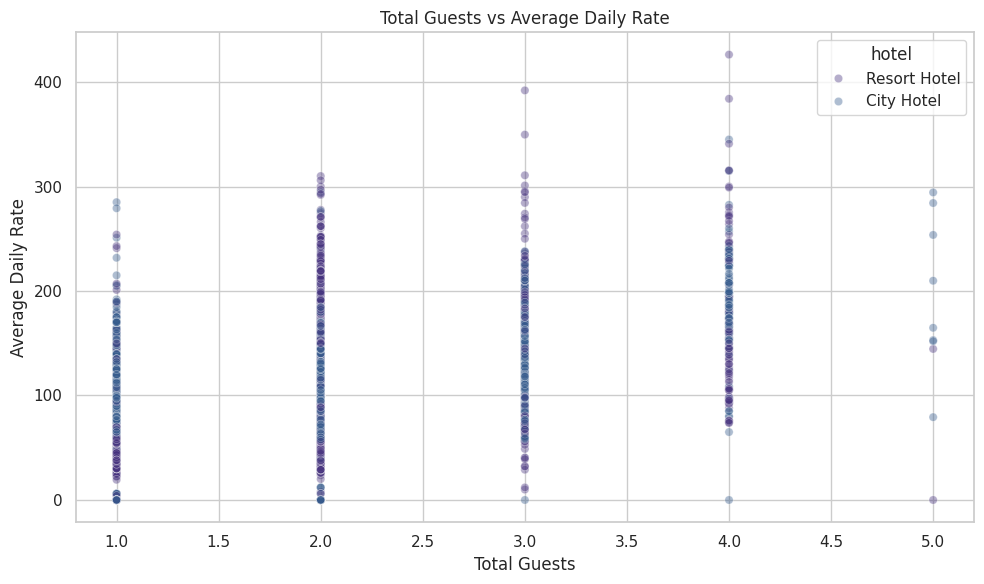

In [86]:
s = df[df['total_guests'] <= 6].sample(5000, random_state=42)
plt.figure(figsize=(10,6))
sns.scatterplot(data=s, x='total_guests', y='avg_daily_rate', alpha=0.4, hue='hotel')
plt.title('Total Guests vs Average Daily Rate'); plt.xlabel('Total Guests'); plt.ylabel('Average Daily Rate')
save(4)

5.5 Line Chart (monthly price trend by hotel)

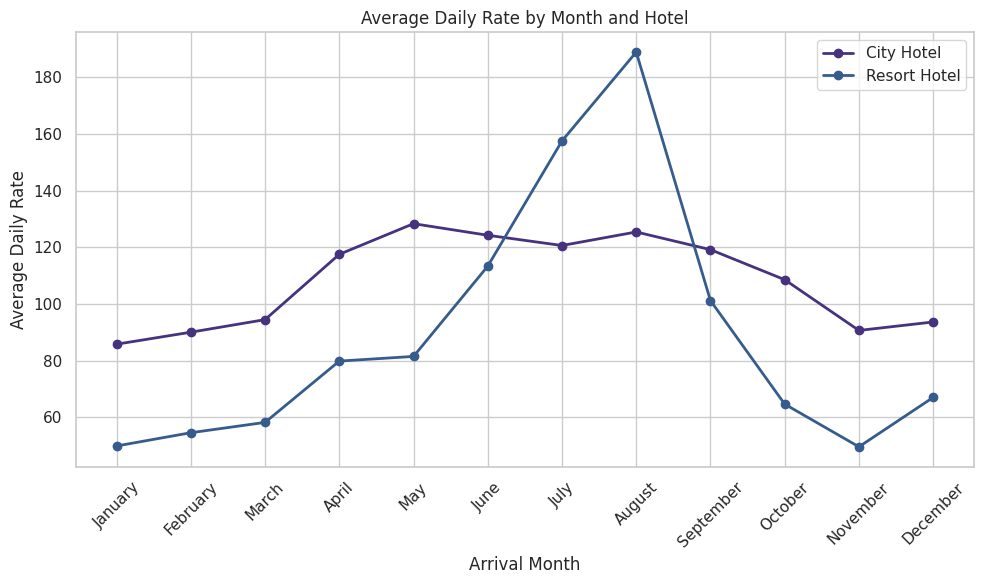

In [87]:
m = df.groupby(['arrival_month','hotel'])['avg_daily_rate'].mean().unstack().reindex(month_order)
plt.figure(figsize=(10,6))
for h in m.columns:
    plt.plot(m.index, m[h], marker='o', linewidth=2, label=h)
plt.title('Average Daily Rate by Month and Hotel'); plt.xlabel('Arrival Month'); plt.ylabel('Average Daily Rate')
plt.xticks(rotation=45); plt.legend(); save(5)

5.6 Box Plot (rate by hotel)

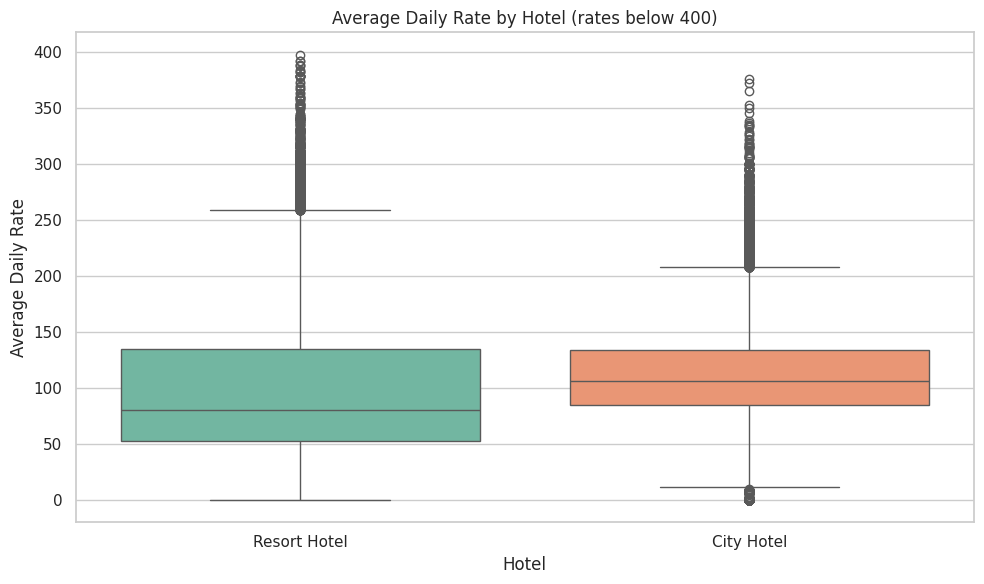

In [88]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[df['avg_daily_rate'] < 400], x='hotel', y='avg_daily_rate', palette='Set2')
plt.title('Average Daily Rate by Hotel (rates below 400)'); plt.xlabel('Hotel'); plt.ylabel('Average Daily Rate')
save(6)

5.7 Correlation Heatmap

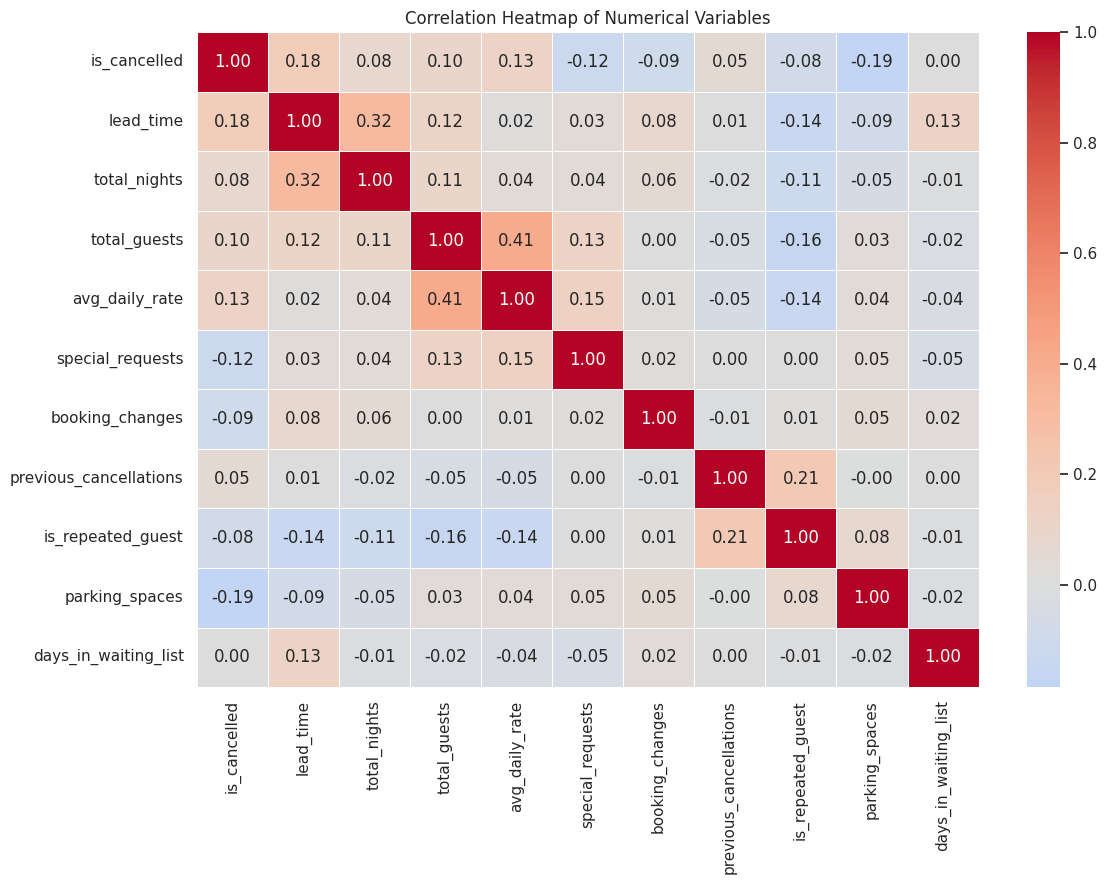

In [89]:
plt.figure(figsize=(12,9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Variables'); save(7)

5.8 Count Plot (market segment vs cancellation)

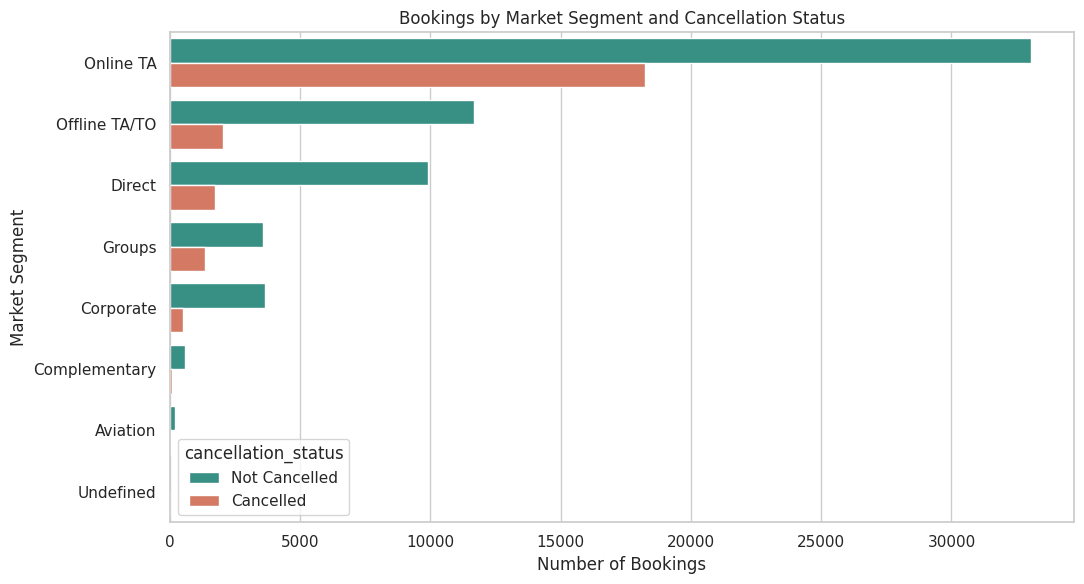

In [90]:
plt.figure(figsize=(11,6))
sns.countplot(data=df, y='market_segment', hue='cancellation_status',
              order=df['market_segment'].value_counts().index, palette=['#2a9d8f','#e76f51'])
plt.title('Bookings by Market Segment and Cancellation Status'); plt.xlabel('Number of Bookings'); plt.ylabel('Market Segment')
save(8)

5.9 Pair Plot (thoda time lega, bas 30 se 60 second)

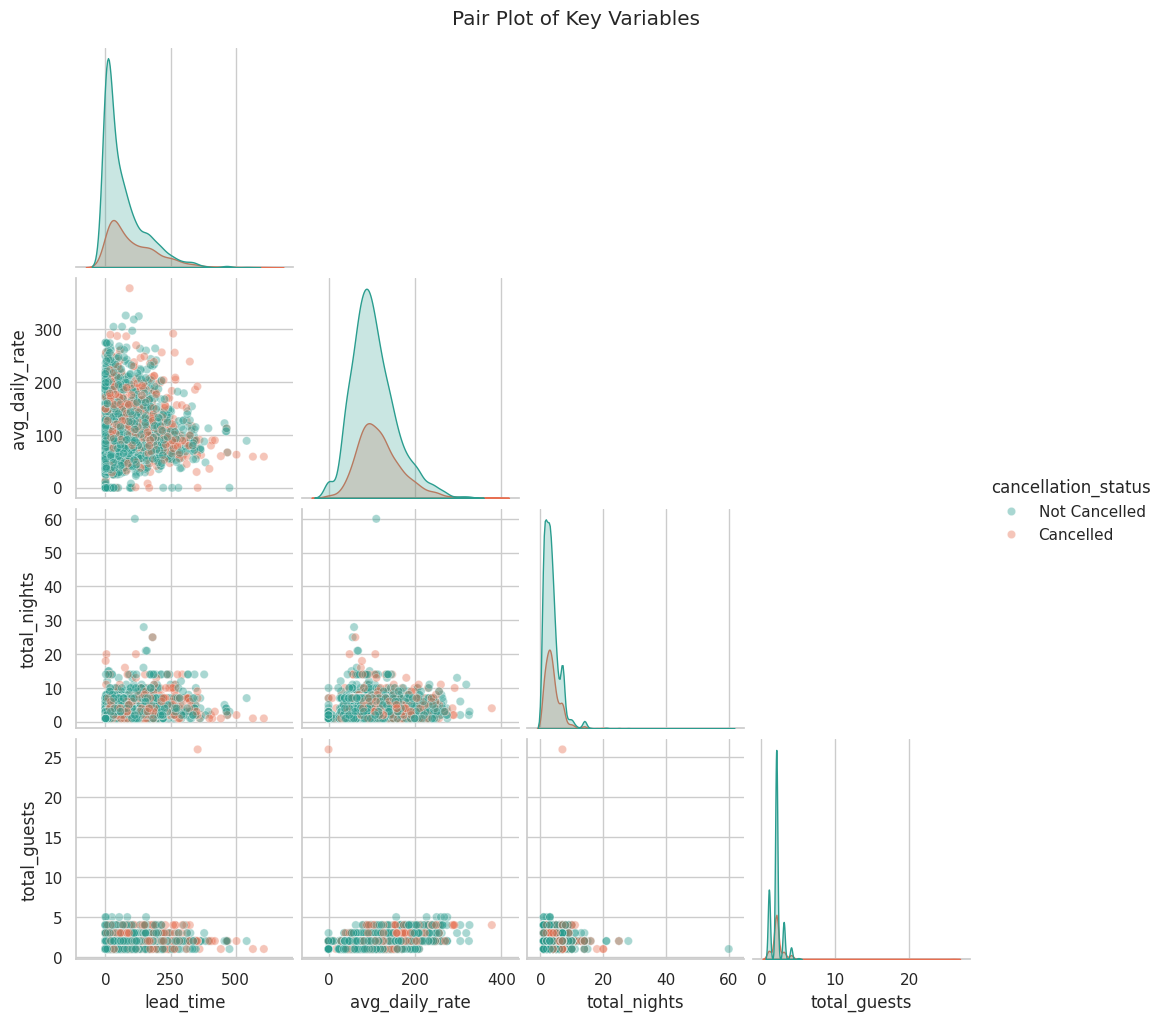

In [91]:
ps = df[['lead_time','avg_daily_rate','total_nights','total_guests','cancellation_status']].sample(3000, random_state=42)
g = sns.pairplot(ps, hue='cancellation_status', palette=['#2a9d8f','#e76f51'], corner=True, plot_kws={'alpha':0.4})
g.fig.suptitle('Pair Plot of Key Variables', y=1.02)
g.fig.savefig(f'{IMG}visualization_09.png', dpi=300, bbox_inches='tight'); plt.show()

5.10 Violin Plot (lead time vs cancellation)

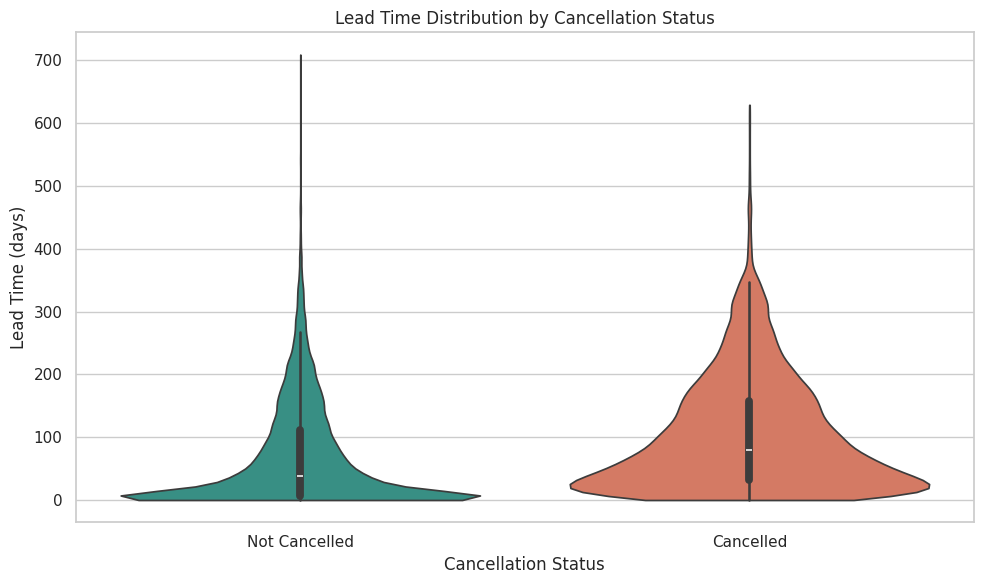

In [92]:
plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='cancellation_status', y='lead_time', palette=['#2a9d8f','#e76f51'], cut=0)
plt.title('Lead Time Distribution by Cancellation Status'); plt.xlabel('Cancellation Status'); plt.ylabel('Lead Time (days)')
save(10)

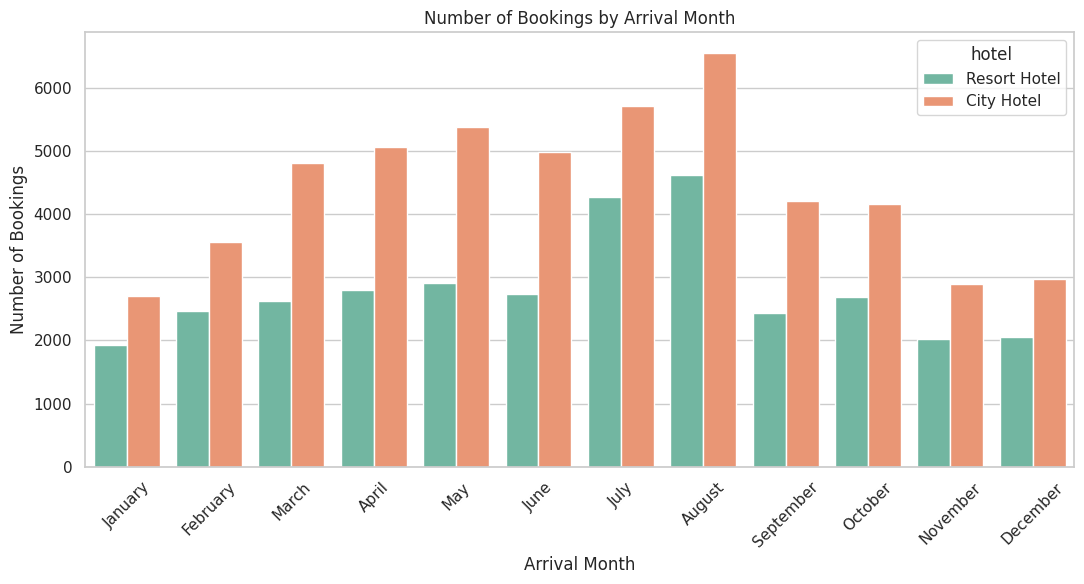

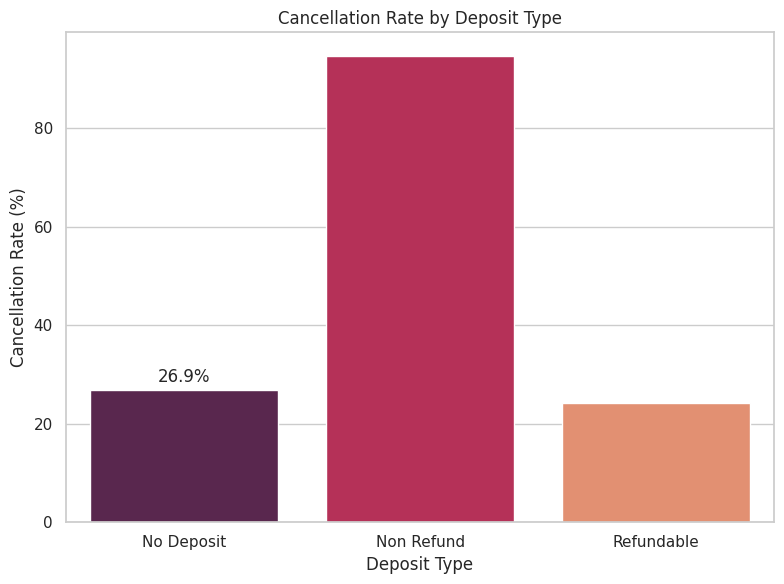

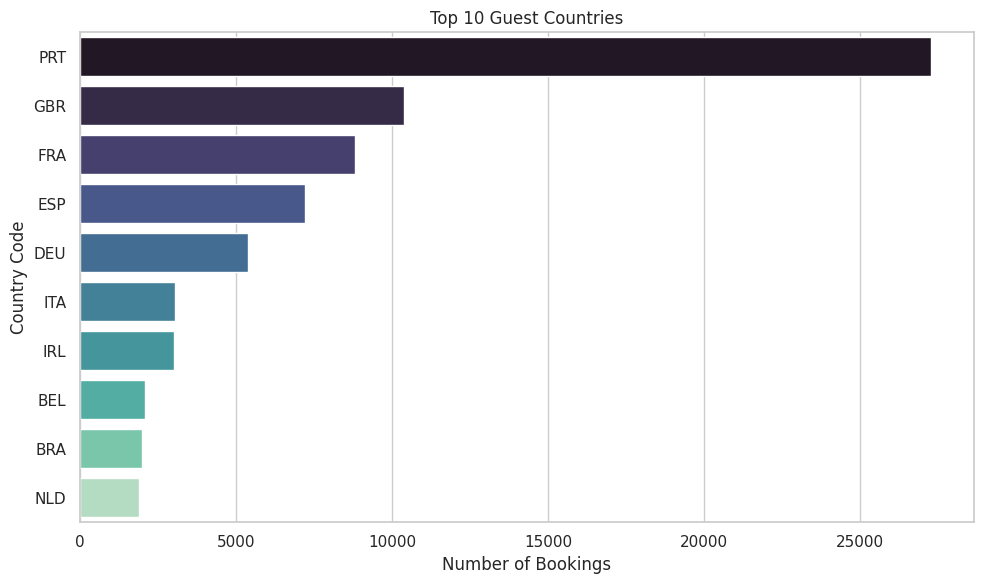

In [93]:
# 11: bookings per month
plt.figure(figsize=(11,6))
sns.countplot(data=df, x='arrival_month', order=month_order, hue='hotel', palette='Set2')
plt.title('Number of Bookings by Arrival Month'); plt.xlabel('Arrival Month'); plt.ylabel('Number of Bookings')
plt.xticks(rotation=45); save(11)

# 12: cancellation rate by deposit type
dep = df.groupby('deposit_type')['is_cancelled'].mean()*100
plt.figure(figsize=(8,6))
ax = sns.barplot(x=dep.index, y=dep.values, palette='rocket')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
plt.title('Cancellation Rate by Deposit Type'); plt.xlabel('Deposit Type'); plt.ylabel('Cancellation Rate (%)')
save(12)

# 13: top 10 countries
plt.figure(figsize=(10,6))
c10 = df['country'].value_counts().head(10)
sns.barplot(x=c10.values, y=c10.index, palette='mako')
plt.title('Top 10 Guest Countries'); plt.xlabel('Number of Bookings'); plt.ylabel('Country Code')
save(13)

### 5.14 Interpretation of Visualizations

**Chart 1: Histogram of Lead Time**
The histogram shows how many days before arrival guests make their bookings. The distribution is strongly right-skewed: most bookings are made a short time before arrival, while a small number are made more than a year ahead (maximum 709 days). The mean (80.31 days) is higher than the median (50 days), so a few very early bookings pull the average up. This matters because hotels cannot assume that guests plan far in advance; many bookings arrive at short notice.

**Chart 2: Average Daily Rate by Market Segment**
The bar chart compares the average price per night across booking channels. Online TA (118.91) and Direct (118.08) have the highest rates, while Corporate (69.17) and Groups (75.60) have the lowest. This suggests that individual online and direct guests pay full prices, whereas corporate and group bookings receive negotiated discounts. Hotels can use this to decide which channels to promote for higher revenue.

**Chart 3: Share of Bookings by Market Segment**
The pie chart shows that Online TA accounts for about 59% of all bookings, followed by Offline TA/TO (about 16%) and Direct (about 13%). Online travel agents are therefore the main source of business. This is important because the hotels depend heavily on a single channel, which also affects cancellation levels.

**Chart 4: Total Guests vs Average Daily Rate (Scatter Plot)**
The scatter plot shows that bookings with more guests tend to have a higher daily rate. This agrees with the correlation of 0.41, the strongest relationship in the dataset. The reason is that the price of a booking grows with the number of people. The points are widely spread, which shows that other factors such as season and hotel also affect price.

**Chart 5: Average Daily Rate by Month and Hotel (Line Chart)**
The line chart shows a clear seasonal pattern. Prices rise from about 71 in January to a peak of about 152 in August, then fall again towards winter. Summer is the high season and winter the low season. Hotels can use this pattern for pricing and for planning staff and promotions.

**Chart 6: Average Daily Rate by Hotel (Box Plot)**
The box plot compares the spread of prices at the two hotels. The City Hotel has a higher average rate (111.66) than the Resort Hotel (100.15). Points above the whiskers are outliers, which are high-priced bookings, mostly in peak season. These were kept because they are genuine bookings.

**Chart 7: Correlation Heatmap**
The heatmap summarises the relationships between numerical variables. The strongest correlation is between total guests and average daily rate (0.41), followed by lead time and total nights (0.32). All correlations with cancellation are weak (the highest is parking_spaces at −0.19 and lead_time at 0.18). This means that no single variable can predict cancellation on its own.

**Chart 8: Bookings by Market Segment and Cancellation Status (Count Plot)**
The count plot shows the number of cancelled and non-cancelled bookings in each segment. Online TA has by far the most bookings and also the highest cancellation rate (35.55%), while Corporate (12.23%) and Direct (14.88%) cancel much less. Online bookings are easy to make and to cancel, so they carry more risk for hotels.

**Chart 9: Pair Plot of Key Variables**
The pair plot shows the relationships between lead time, daily rate, total nights and total guests, coloured by cancellation status. Most variables show weak relationships, which matches the heatmap. The cancelled bookings are spread over the same ranges as the non-cancelled ones, which confirms that cancellation cannot be separated by these variables alone.

**Chart 10: Lead Time by Cancellation Status (Violin Plot)**
The violin plot shows that cancelled bookings were made much earlier (average 105.8 days) than non-cancelled bookings (average 70.5 days). Bookings made far in advance have more time to be cancelled because plans change. Hotels can watch long lead-time bookings more closely.

**Chart 11: Number of Bookings by Arrival Month**
August is the busiest month (11,194 bookings) and January the quietest (4,636). Bookings rise through spring, peak in summer and drop in autumn and winter. This matches the price pattern in Chart 5, so demand and price rise together.

**Chart 12: Cancellation Rate by Deposit Type**
Non Refund bookings have a cancellation rate of 94.70%, compared with 26.88% for No Deposit and 24.30% for Refundable. This is an unexpected result, because guests who pay in advance would be expected to cancel less. It may reflect how this hotel group labels bookings made through certain channels, and it should be treated with caution.

**Chart 13: Top 10 Guest Countries**
Portugal (PRT) is the largest source of guests with 27,282 bookings, followed by Great Britain (10,399), France (8,813), Spain (7,228) and Germany (5,385). Most guests come from Portugal and nearby European countries, which shows that the hotels mainly serve the European market.

## 6. Insights & Findings

**Insight 1: About one in four bookings is cancelled.**
The overall cancellation rate is 27.69%. For a hotel, every cancelled booking is a room that may stay empty, so cancellations directly reduce revenue.

**Insight 2: The City Hotel has more cancellations than the Resort Hotel.**
The City Hotel cancellation rate is 30.21% compared with 23.72% for the Resort Hotel. City guests (often business or short-trip travellers) change plans more easily than holiday guests.

**Insight 3: Online travel agents bring the most bookings and the most cancellations.**
Online TA makes up 59.21% of all bookings and has the highest cancellation rate of the main segments (35.55%). The hotels depend heavily on a channel that is also the least reliable.

**Insight 4: Corporate and Direct bookings are the most reliable.**
Their cancellation rates are only 12.23% (Corporate) and 14.88% (Direct), less than half of the Online TA rate. Encouraging direct bookings can reduce cancellation losses.

**Insight 5: Bookings made earlier are more likely to be cancelled.**
Cancelled bookings were made on average 105.8 days before arrival, compared with 70.5 days for completed ones. Lead time also has one of the strongest correlations with cancellation (r = 0.18).

**Insight 6: Lead time is highly skewed.**
The mean lead time is 80.31 days but the median is only 50 days, and the most common value (mode) is 0, meaning same-day bookings. The maximum is 709 days. The median describes a typical booking better than the mean.

**Insight 7: Strong seasonality in demand and price.**
August is the busiest month (11,194 bookings) with the highest average daily rate (151.70), while January is the quietest (4,636 bookings) with a rate of 70.89. The August rate is more than twice the January rate, so demand and price rise together in summer.

**Insight 8: The City Hotel charges more than the Resort Hotel.**
The average daily rate is 111.66 for the City Hotel and 100.15 for the Resort Hotel, about 11.5% higher, even though the City Hotel also has more bookings (53,040 vs 33,571).

**Insight 9: Number of guests is the strongest driver of price.**
Total guests and average daily rate have the strongest correlation in the dataset (r = 0.41). Lead time and total nights are the next strongest pair (r = 0.32), showing that early bookings tend to be for longer stays.

**Insight 10: Guests who ask for parking or special services cancel less.**
Parking spaces (r = −0.19) and special requests (r = −0.12) are negatively related to cancellation. Guests who plan details of their stay are more committed to it.

**Insight 11: Online and Direct bookings pay the highest rates, Corporate and Groups the lowest.**
Online TA averages 118.91 and Direct 118.08, while Corporate averages 69.17, about 42% lower than Online TA. Discounted contracts bring volume but lower revenue per night.

**Insight 12: Almost all bookings are made without a deposit.**
No Deposit accounts for 98.68% of bookings. Unexpectedly, the small Non Refund group has a cancellation rate of 94.70%, far above No Deposit (26.88%), which is an unusual pattern worth investigating further.

**Insight 13: Most guests are transient European travellers.**
Transient customers make up 82.38% of bookings and Portugal alone supplies 27,282 bookings (31.5%), followed by Great Britain, France, Spain and Germany. A typical booking has 2 guests and a stay of 3 nights.

**Insight 14: Variation differs widely between variables.**
booking_changes has the highest relative variation (coefficient of variation 264.7%) and total_guests the lowest (38.9%). Booking changes are rare but very uneven, while group size is quite uniform.

**Insight 15: Outliers are genuine and limited.**
Only 2.72% of lead times, 2.90% of daily rates and 3.45% of stay lengths are outliers. They represent real unusual bookings, so they were kept.

**Overall pattern:** no single variable strongly predicts cancellation (all correlations are below 0.20 in absolute value). Cancellation depends on a combination of factors such as channel, hotel, lead time and guest behaviour, which is why machine learning models will be useful in later tasks.

In [94]:
df.to_csv('/content/drive/MyDrive/Task_01_AI_ML/dataset/cleaned_hotel_bookings.csv', index=False)
print("Saved:", df.shape)

Saved: (86611, 35)
